## Clustering: Planteamiento y preparación

Preguntas de interés, selección de features, estandarización y PCA sobre `features_proveedor` (Parte I)

---
### **0. Preguntas de interés**

**PQ-C1. Segmentación estructural**

- ¿Existen **arquetipos** de proveedores del Estado según especialización (bienes, servicios, obras), escala económica y
  alcance (entidades, regiones, rubros)?
- ¿O el mercado está **polarizado** entre pocos megacontratistas multipropósito y una masa de microproveedores
  atomizados?

**PQ-C2. Anomalías como banderas de auditoría**

- ¿Qué proveedores combinan de forma atípica **monto adjudicado alto**, **pocos procesos** y **alta concentración en
  pocas entidades**?
- ¿Son casos aislados (ruido de densidad) o forman un grupo propio?

**Por qué importa**

- El SEACE registra cientos de miles de procesos al año; el OECE y la Contraloría **no pueden revisarlos todos**:
  priorizar dónde mirar es el problema práctico
- Los arquetipos permiten comparar a cada proveedor **con sus pares** (una constructora frente a constructoras), en
  lugar de contra el promedio de todo el mercado
- La dependencia de una sola entidad y el postor único son indicadores de riesgo usados en contratación pública
  (OCDE, *Preventing Corruption in Public Procurement*); aquí se miden de forma combinada, no aislada
- **Encuadre:** los resultados son **señales descriptivas para priorizar revisión**, nunca evidencia de irregularidad
  (§6 de `c_interpretacion`)

---
### Constantes

- `VAR_OBJ`: varianza acumulada mínima a retener en el PCA

In [1]:
VAR_OBJ = 0.80

### Utilidades

In [2]:
NOTEBOOK = "a_preparacion"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 8
Memoria driver: 3.0 GB
UI del job    : http://localhost:4040


---
### **1. Carga y features**

#### a. Vectores de la Parte I y dispersión de montos

- `features_proveedor` no trae la **dispersión** de montos: se calcula en Spark desde `data/final/hechos`
- Dispersión = desviación estándar de log(monto) entre las adjudicaciones de cada proveedor

In [4]:
hechos = leer(final_dir, "hechos")
disp = (hechos.groupBy("ocid", "award_id", "proveedor_key").agg(F.sum("monto_asignado").alias("m"))
              .groupBy("proveedor_key").agg(F.stddev_samp(F.log1p("m")).alias("disp_log_monto")))
nombres = leer(final_dir, "proveedores").select("proveedor_key", "nombre", "region")

df = (leer(artef_dir, "features_proveedor").drop("features_raw")
        .join(disp, "proveedor_key", "left").join(nombres, "proveedor_key", "left").toPandas())
df["disp_log_monto"] = df.disp_log_monto.fillna(0)  # con una sola adjudicación no hay dispersión
sin_monto = df.monto_total.isna()
print(f"proveedores: {len(df):,} | sin monto adjudicado (se excluyen): {sin_monto.sum()}")
df = df[~sin_monto].reset_index(drop=True)
df.proveedor_key.str.split(":").str[0].value_counts().to_frame("proveedores").T

proveedores: 86,032 | sin monto adjudicado (se excluyen): 21


proveedor_key,CONS,RUC,PN,EXT,NOM
proveedores,42407,26290,14711,2602,1


- **Sin monto (21):** su `log_monto` se rellenó con 0 en la Parte I; dejarlos crearía outliers artificiales
- **Consorcios ≈ 49%** de los proveedores: en el SEACE cada consorcio es una figura temporal por proceso, por eso casi
  todos tienen un solo contrato

#### b. Selección de features

| Dimensión | Feature | Transformación | Qué captura |
|---|---|---|---|
| Económica | `log_monto_total` | log1p | escala total adjudicada |
| | `log_monto_mediano` | log1p | tamaño típico de un contrato |
| | `disp_log_monto` | — | heterogeneidad de montos (contratos chicos y grandes) |
| Operativa | `log_n_procesos` | log1p | frecuencia: contratos ganados |
| | `log_n_entidades` | log1p | cartera de clientes públicos |
| | `log_meses_activos` | log1p | permanencia en el mercado |
| | `tasa_exito` | — | ganadas / ofertas |
| Competencia | `pct_postor_unico` | — | % de adjudicaciones sin competencia |
| | `pct_directa` | — | % por contratación directa |
| | `hhi_entidades` | — | concentración del monto en pocas entidades (1 = una sola) |
| Mercado | `log_n_familias` | log1p | diversidad de rubros UNSPSC |
| | `log_n_regiones` | log1p | cobertura territorial |
| | `pct_bienes`, `pct_obras` | — | especialización (servicios = 1 − bienes − obras) |
| | `es_consorcio` | — | figura asociativa temporal |

- **log1p** en conteos y montos: colas pesadas (p99 de monto total S/ 40M vs. mediana S/ 0.3M)

In [5]:
for c in ["n_entidades", "meses_activos", "n_familias", "n_regiones"]:
    df[f"log_{c}"] = np.log1p(df[c])

FEATS = ["log_monto_total", "log_monto_mediano", "disp_log_monto",
         "log_n_procesos", "log_n_entidades", "log_meses_activos", "tasa_exito",
         "pct_postor_unico", "pct_directa", "hhi_entidades",
         "log_n_familias", "log_n_regiones", "pct_bienes", "pct_obras", "es_consorcio"]
ORIG = ["monto_total", "monto_mediano", "n_procesos", "n_entidades", "n_regiones", "n_familias", "meses_activos",
        "tasa_exito", "pct_postor_unico", "pct_directa", "hhi_entidades", "pct_bienes", "pct_servicios", "pct_obras",
        "es_consorcio"]

descartes = pd.DataFrame([
    ("compite", "desv. estándar", round(df.compite.std(), 4)),
    ("n_ganadas_compitiendo", "corr. con n_procesos", round(df[["n_ganadas_compitiendo", "n_procesos"]].corr().iloc[0, 1], 3)),
    ("share_top_entidades", "corr. con hhi_entidades", round(df[["share_top_entidades", "hhi_entidades"]].corr().iloc[0, 1], 3)),
    ("pct_servicios", "= 1 − bienes − obras", round((1 - df.pct_bienes - df.pct_obras - df.pct_servicios).abs().max(), 4))],
    columns=["descartada", "criterio", "valor"])
descartes

,descartada,criterio,valor
0,compite,desv. estándar,0.0048
1,n_ganadas_compitiendo,corr. con n_procesos,1.0000
2,share_top_entidades,corr. con hhi_entidades,0.9920
3,pct_servicios,= 1 − bienes − obras,0.0000


- **Descartadas:** `compite` no varía; `n_ganadas_compitiendo` y `share_top` duplican a otra variable; `pct_servicios`
  es combinación exacta de las otras dos (colinealidad perfecta)

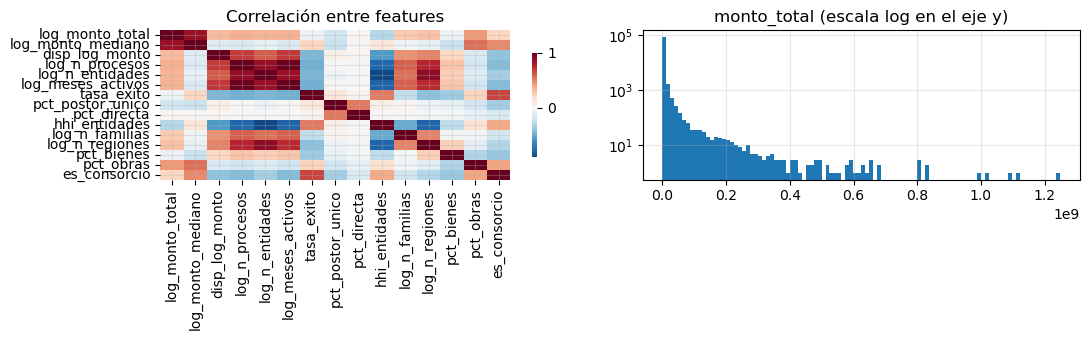

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.heatmap(df[FEATS].corr(), cmap="RdBu_r", center=0, ax=ax[0], cbar_kws={"shrink": .7})
ax[0].set_title("Correlación entre features")
ax[1].hist(df.monto_total, bins=100, log=True); ax[1].set_title("monto_total (escala log en el eje y)")
mostrar_fig("features")

- Los bloques de correlación (montos entre sí; procesos, entidades y meses entre sí) justifican el PCA: varias
  features miden lo mismo y, sin reducir, ese factor pesaría doble en la distancia euclidiana

---
### **2. Estandarización**

- Se compara `RobustScaler` (mediana / rango intercuartil) con `StandardScaler` (media / desviación)

In [7]:
q = df[FEATS].quantile([.25, .75])
iqr = (q.loc[.75] - q.loc[.25]).rename("IQR")
iqr_cero = iqr[iqr == 0].index.tolist()
print(f"features con IQR = 0: {len(iqr_cero)} de {len(FEATS)} → {iqr_cero}")

features con IQR = 0: 10 de 15 → ['disp_log_monto', 'log_n_procesos', 'log_n_entidades', 'log_meses_activos', 'pct_postor_unico', 'pct_directa', 'hhi_entidades', 'log_n_familias', 'log_n_regiones', 'pct_obras']


- **RobustScaler no sirve aquí:** el proveedor mediano tiene 1 proceso, 1 entidad y 1 región, así que más de la mitad
  de las features tiene IQR = 0 y no se escalarían (sklearn deja la escala en 1), mezclando unidades
- **StandardScaler tras log1p:** el log ya domó las colas pesadas, que era la razón para preferir el escalado robusto;
  la media y la desviación quedan bien definidas para todas las features

In [8]:
X = StandardScaler().fit_transform(df[FEATS])
pd.DataFrame(X, columns=FEATS).describe().loc[["mean", "std", "min", "max"]].round(2)

,log_monto_total,log_monto_mediano,disp_log_monto,log_n_procesos,log_n_entidades,log_meses_activos,tasa_exito,pct_postor_unico,pct_directa,hhi_entidades,log_n_familias,log_n_regiones,pct_bienes,pct_obras,es_consorcio
mean,-0.00,0.00,-0.00,-0.00,-0.00,0.00,0.00,-0.00,-0.00,0.00,-0.00,0.00,0.00,0.0,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00
min,-7.37,-7.51,-0.41,-0.44,-0.34,-0.44,-1.90,-0.40,-0.29,-4.41,-2.41,-0.29,-0.59,-0.5,-0.99
max,4.66,5.09,37.71,12.41,12.91,6.25,0.69,2.64,3.66,0.39,8.91,13.98,1.74,2.0,1.01


---
### **3. PCA**

- **Por qué:** descorrelaciona los bloques de features redundantes (cada factor pesa una vez) y reduce el costo de
  KMeans/DBSCAN, cuyo cálculo de vecinos se degrada con la dimensión

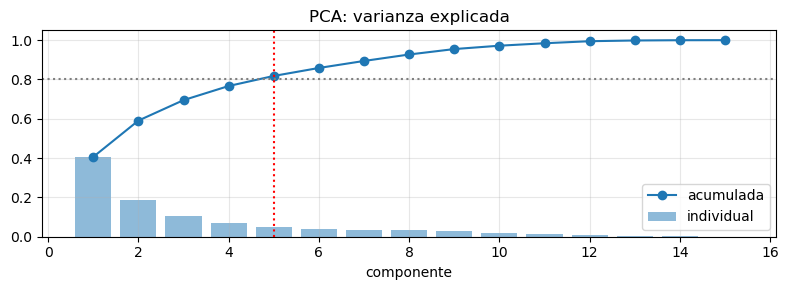

componentes para ≥ 80%: 5 (81.8%) | criterio de Kaiser (λ > 1): 4


In [9]:
pca_full = PCA(random_state=SEMILLA).fit(X)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)
n_comp = int(np.searchsorted(var_acum, VAR_OBJ) + 1)
kaiser = int((pca_full.explained_variance_ > 1).sum())

plt.figure(figsize=(8, 3))
plt.bar(range(1, len(FEATS) + 1), pca_full.explained_variance_ratio_, alpha=.5, label="individual")
plt.plot(range(1, len(FEATS) + 1), var_acum, "o-", label="acumulada")
plt.axhline(VAR_OBJ, ls=":", color="gray"); plt.axvline(n_comp, ls=":", color="red")
plt.title("PCA: varianza explicada"); plt.xlabel("componente"); plt.legend(); mostrar_fig("pca_varianza")
print(f"componentes para ≥ {VAR_OBJ:.0%}: {n_comp} ({var_acum[n_comp - 1]:.1%}) | criterio de Kaiser (λ > 1): {kaiser}")

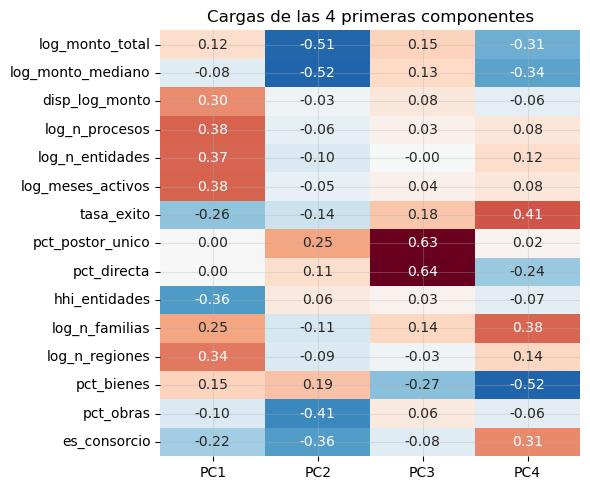

In [10]:
pca = PCA(n_components=n_comp, random_state=SEMILLA)
P = pca.fit_transform(X)
cargas = pd.DataFrame(pca.components_[:4].T, index=FEATS, columns=[f"PC{i}" for i in range(1, 5)])
plt.figure(figsize=(6, 5)); sns.heatmap(cargas, cmap="RdBu_r", center=0, annot=True, fmt=".2f", cbar=False)
plt.title("Cargas de las 4 primeras componentes"); mostrar_fig("pca_cargas")

- **5 componentes** retienen el 81.8% de la varianza; Kaiser sugiere 4 (76.7%). Se usa 5 para cumplir el 80% sin
  perder la componente de especialización en bienes
- **PC1 (40.6%) actividad y alcance:** crece con procesos, entidades, meses, regiones y rubros; baja con el HHI. Separa al
  proveedor recurrente y diversificado del ocasional de un solo cliente
- **PC2 (18.5%) tamaño y tipo de contrato:** negativo = montos altos, obras y consorcios; positivo = bienes y postor
  único. Es el eje "obra grande" vs. "compra menor"
- **PC3 (10.4%) ausencia de competencia:** postor único y contratación directa
- **PC4 (7.2%) bienes vs. diversificación:** bienes (−) frente a tasa de éxito y número de rubros (+)

---
### **4. Escritura**

- `data/clustering/preparado.parquet`: clave, nombre, variables originales, features y componentes

In [11]:
PCS = [f"pc_{i}" for i in range(1, n_comp + 1)]
prep = pd.concat([df[["proveedor_key", "nombre", "region"] + ORIG + [f for f in FEATS if f not in ORIG]],
                  pd.DataFrame(P, columns=PCS)], axis=1)
prep.to_parquet(clust_dir / "preparado.parquet", index=False)

var_tabla = pd.DataFrame({"componente": range(1, len(FEATS) + 1), "varianza": pca_full.explained_variance_ratio_,
                          "acumulada": var_acum})
escritos = guardar_tablas({"pca_varianza": var_tabla, "pca_cargas": cargas.reset_index(names="feature"),
                           "descartes": descartes})
print(f"preparado: {prep.shape[0]:,} proveedores × {len(PCS)} componentes")

Escrito en 02_Clustering/temp/a_preparacion/: pca_varianza, pca_cargas, descartes
preparado: 86,011 proveedores × 5 componentes


In [12]:
verificar_salidas(escritos)

OK: 3 tablas (parquet + json) | 3 figuras: features, pca_cargas, pca_varianza


---
### Cerrar sesión

In [13]:
spark.stop()